Conjunto de Vinho

/tmp/ipykernel_16342/2352506452.py:8: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  wine.rename(columns={"quality": "y_Qualidade"}, inplace=True)


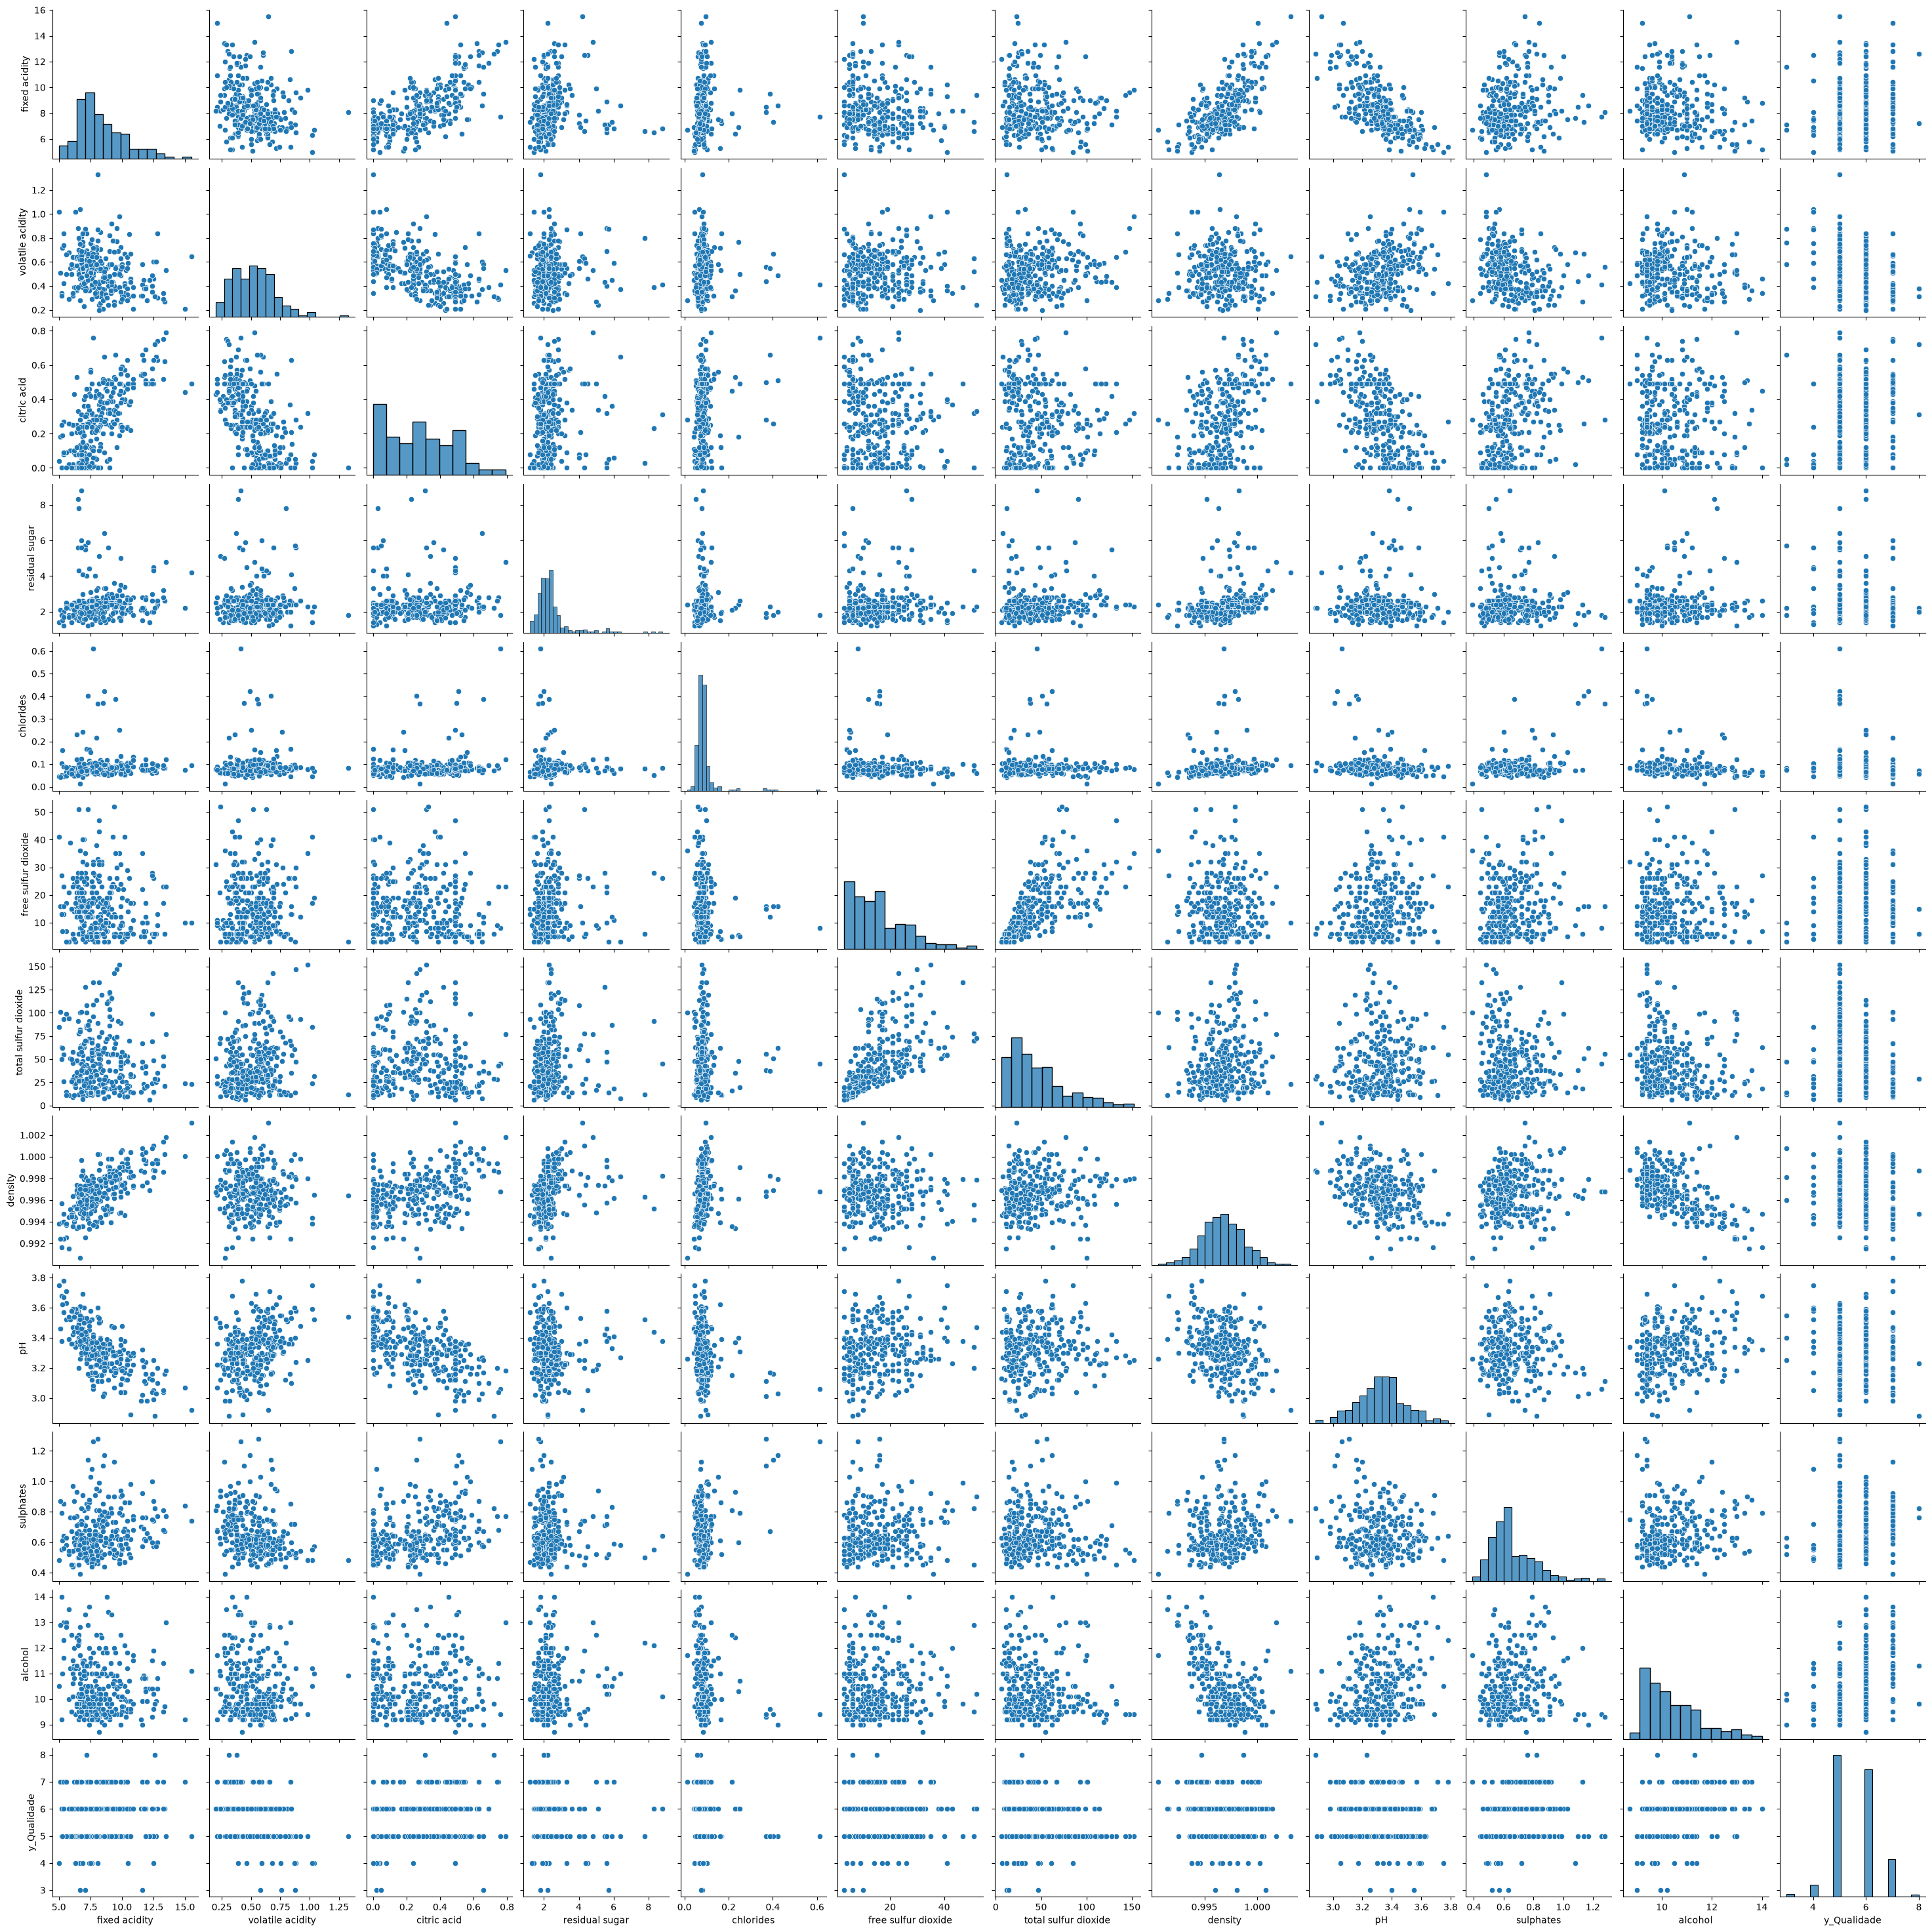

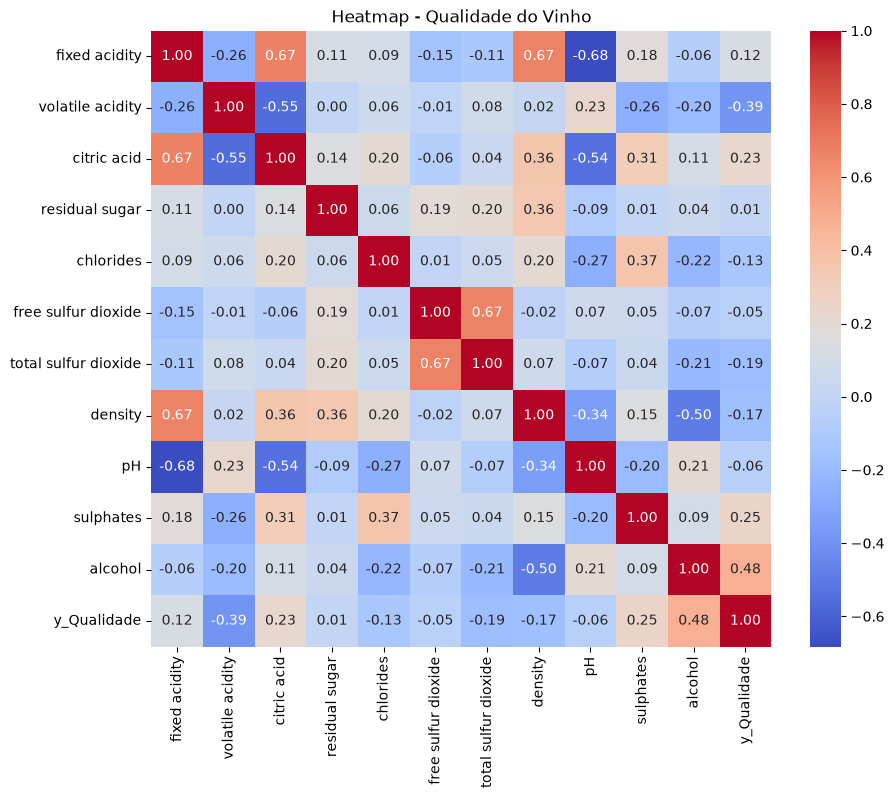

Correlações ordenadas com y_Qualidade:

y_Qualidade             1.000000
alcohol                 0.476166
sulphates               0.251397
citric acid             0.226373
fixed acidity           0.124052
residual sugar          0.013732
free sulfur dioxide    -0.050656
pH                     -0.057731
chlorides              -0.128907
density                -0.174919
total sulfur dioxide   -0.185100
volatile acidity       -0.390558
Name: y_Qualidade, dtype: float64


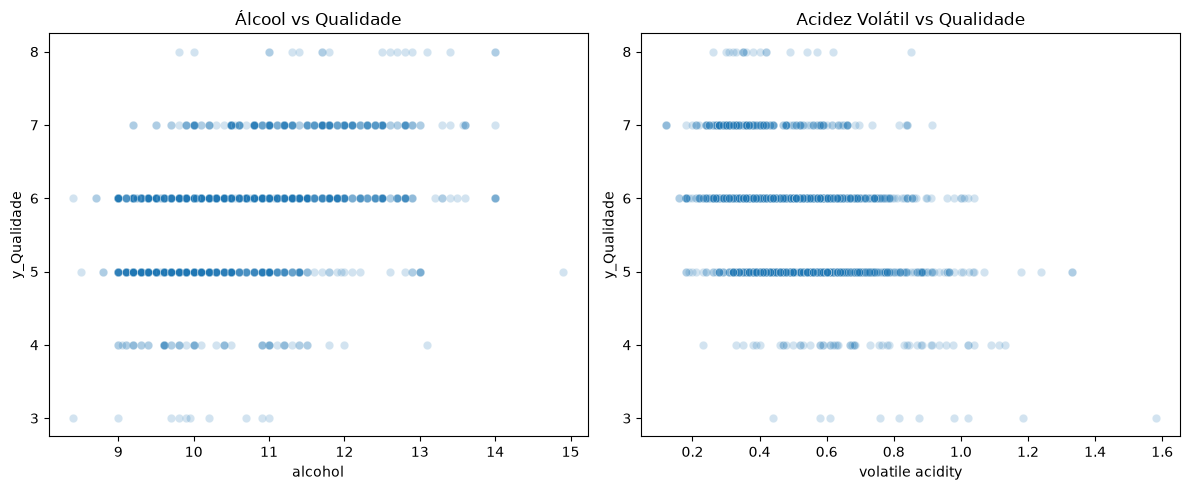

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Carregar dataset público via URL e renomear variável alvo
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv"
wine = pd.read_csv(url, sep=";")
wine.rename(columns={"quality": "y_Qualidade"}, inplace=True)

# 1. Pairplot
sns.pairplot(wine.sample(300))
plt.show()

# 2 e 3. Matriz de Correlação e Heatmap
wine_corr = wine.corr()
plt.figure(figsize=(10, 8))
sns.heatmap(wine_corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Heatmap - Qualidade do Vinho")
plt.show()

# 4. Ordenar correlações com y_Qualidade
corr_alvo = wine_corr["y_Qualidade"].sort_values(ascending=False)
print("Correlações ordenadas com y_Qualidade:\n")
print(corr_alvo)

# 5. Scatterplots de duas variáveis de forte influência vs y_Qualidade
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Variável com maior correlação positiva (alcohol)
sns.scatterplot(data=wine, x="alcohol", y="y_Qualidade", alpha=0.2, ax=axes[0])
axes[0].set_title("Álcool vs Qualidade")

# Variável com maior correlação negativa (volatile acidity)
sns.scatterplot(data=wine, x="volatile acidity", y="y_Qualidade", alpha=0.2, ax=axes[1])
axes[1].set_title("Acidez Volátil vs Qualidade")

plt.tight_layout()
plt.show()

Correlações (4 e 5): 

A variável alcohol (teor alcoólico) lidera como a maior relação positiva (~0.47) e volatile acidity (acidez volátil) é a maior negativa (~ -0.39).

Numérico vs Visual (6): 

Numeramente existem tendências matemáticas concretas (mais álcool tende a elevar a pontuação do vinho). Visualmente, porém, o scatterplot tradicional mascara essas tendências porque a variável y_Qualidade assume apenas notas inteiras fixas (3, 4, 5, 6, 7 e 8). O gráfico forma "faixas verticais" sobrepostas que não revelam bem a densidade sem manipulação extra (como aplicar um modificador alpha de transparência ou adicionar ruído "jitter" na exibição). Isso prova que o número exato da correlação consegue resumir um sinal que uma visualização básica mal adaptada esconde.